<a href="https://colab.research.google.com/github/Kkurzo/-labs/blob/main/%22%D0%9B%D0%A0_7_%D0%9B%D0%BE%D0%B3_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_%D0%B2%D1%80%D1%8F%D1%82%D1%83%D0%B2%D0%B0%D1%82%D0%B8_%D0%BF%D1%80%D0%B8%D0%BD%D1%86%D0%B5%D1%81%D1%83_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26_%D0%9C%D0%B5%D0%BB%D1%8C%D0%BD%D0%B8%D1%87%D1%83%D0%BA_%D0%94%D0%BC%D0%B8%D1%82%D1%80%D0%BE_%D0%A4%D0%86%D0%A2_4_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [79]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("unmoved/cure-the-princess")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cure-the-princess' dataset.
Path to dataset files: /kaggle/input/cure-the-princess


In [80]:
df = pd.read_csv(os.path.join(path, "data.csv"))
df

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2333,9.4,2.2,15.8,5.9,29.7,18.7,11.5,13.1,15.3,22.5,10.1,4.7,13.8,0
2334,12.1,7.6,20.6,5.3,18.9,19.1,9.4,11.9,21.8,12.0,26.7,8.4,24.4,1
2335,15.2,33.2,7.2,14.5,16.0,16.7,1.2,32.5,34.5,25.9,3.9,18.0,19.2,1
2336,2.0,17.0,33.2,13.2,29.1,35.5,19.7,30.3,30.7,4.3,15.7,20.5,2.1,1


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [43]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape

In [81]:
df.head()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [82]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [84]:
df.shape

(2338, 14)

In [ ]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
# Перевірка пропущених значень

In [85]:
df.isnull().sum()

,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


In [86]:
df.duplicated().sum()

np.int64(0)

In [87]:
# TODO: виведіть описову статистику
# Підказка: describe()
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [89]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nКількість цільових значень у навчальній вибірці:")
print(y_train.value_counts())

print("\nКількість цільових значень у тестовій вибірці:")
print(y_test.value_counts())

Розмір навчальної вибірки: (1870, 13)
Розмір тестової вибірки: (468, 13)

Кількість цільових значень у навчальній вибірці:
Cured
0    941
1    929
Name: count, dtype: int64

Кількість цільових значень у тестовій вибірці:
Cured
0    236
1    232
Name: count, dtype: int64


### 5. Баланс класів на навчальній вибірці

In [90]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
class_counts = y_train.value_counts().sort_index()

print(class_counts)

plt.figure(figsize=(7, 5))


Cured
0    941
1    929
Name: count, dtype: int64


<Figure size 700x500 with 0 Axes>

<Figure size 700x500 with 0 Axes>

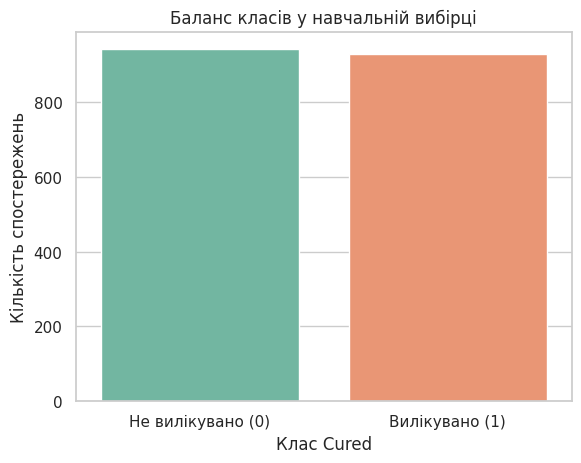

In [91]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)

sns.countplot(
    x=y_train,
    hue=y_train,
    palette='Set2',
    legend=False
)

plt.title('Баланс класів у навчальній вибірці')
plt.xlabel('Клас Cured')
plt.ylabel('Кількість спостережень')
plt.xticks([0, 1], ['Не вилікувано (0)', 'Вилікувано (1)'])

plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

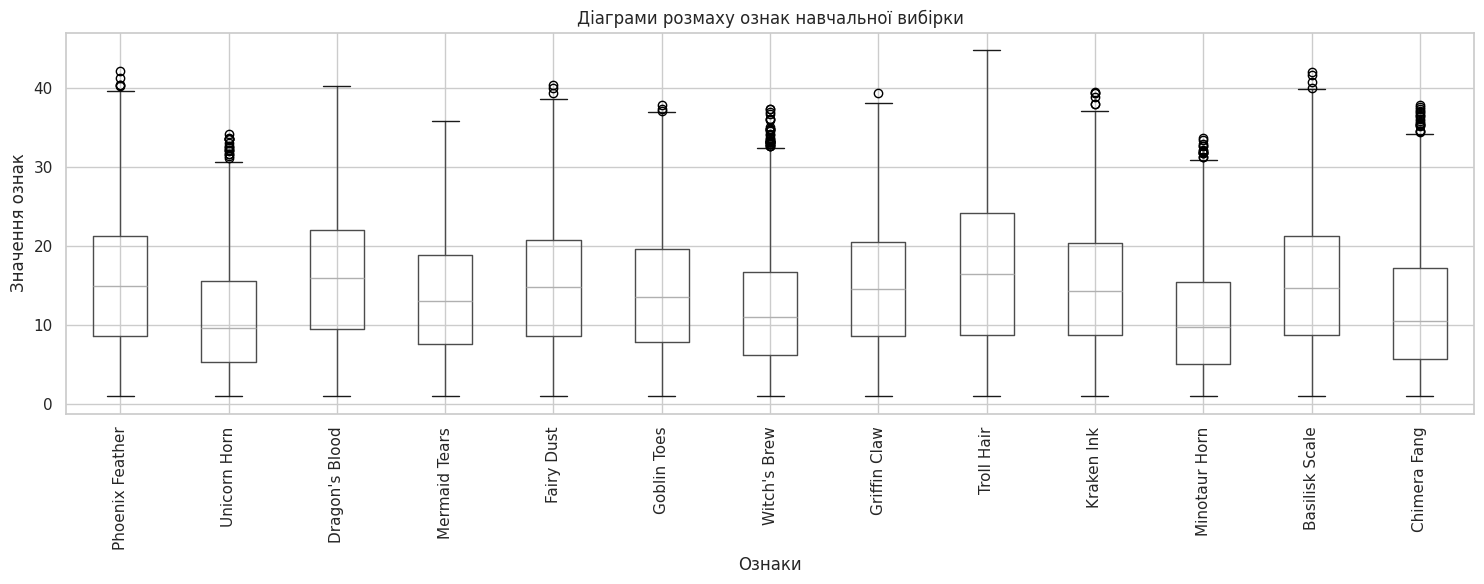

In [92]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
plt.figure(figsize=(15, 6))

X_train.boxplot(
    figsize=(15, 6),
    rot=90
)

plt.title('Діаграми розмаху ознак навчальної вибірки')
plt.ylabel('Значення ознак')
plt.xlabel('Ознаки')

plt.tight_layout()
plt.show()


In [93]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням

q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = (
    (X_train < lower_bound) |
    (X_train > upper_bound)
).sum()
outliers = outliers.sort_values(ascending=False)

display(outliers.to_frame(name='Кількість викидів'))

print(outliers.sum())

print(outliers.idxmax(), "-", outliers.max())

,Кількість викидів
Witch's Brew,31
Chimera Fang,18
Unicorn Horn,17
Minotaur Horn,13
Kraken Ink,6
Phoenix Feather,5
Basilisk Scale,4
Fairy Dust,3
Goblin Toes,3
Griffin Claw,1


101
Witch's Brew - 31


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

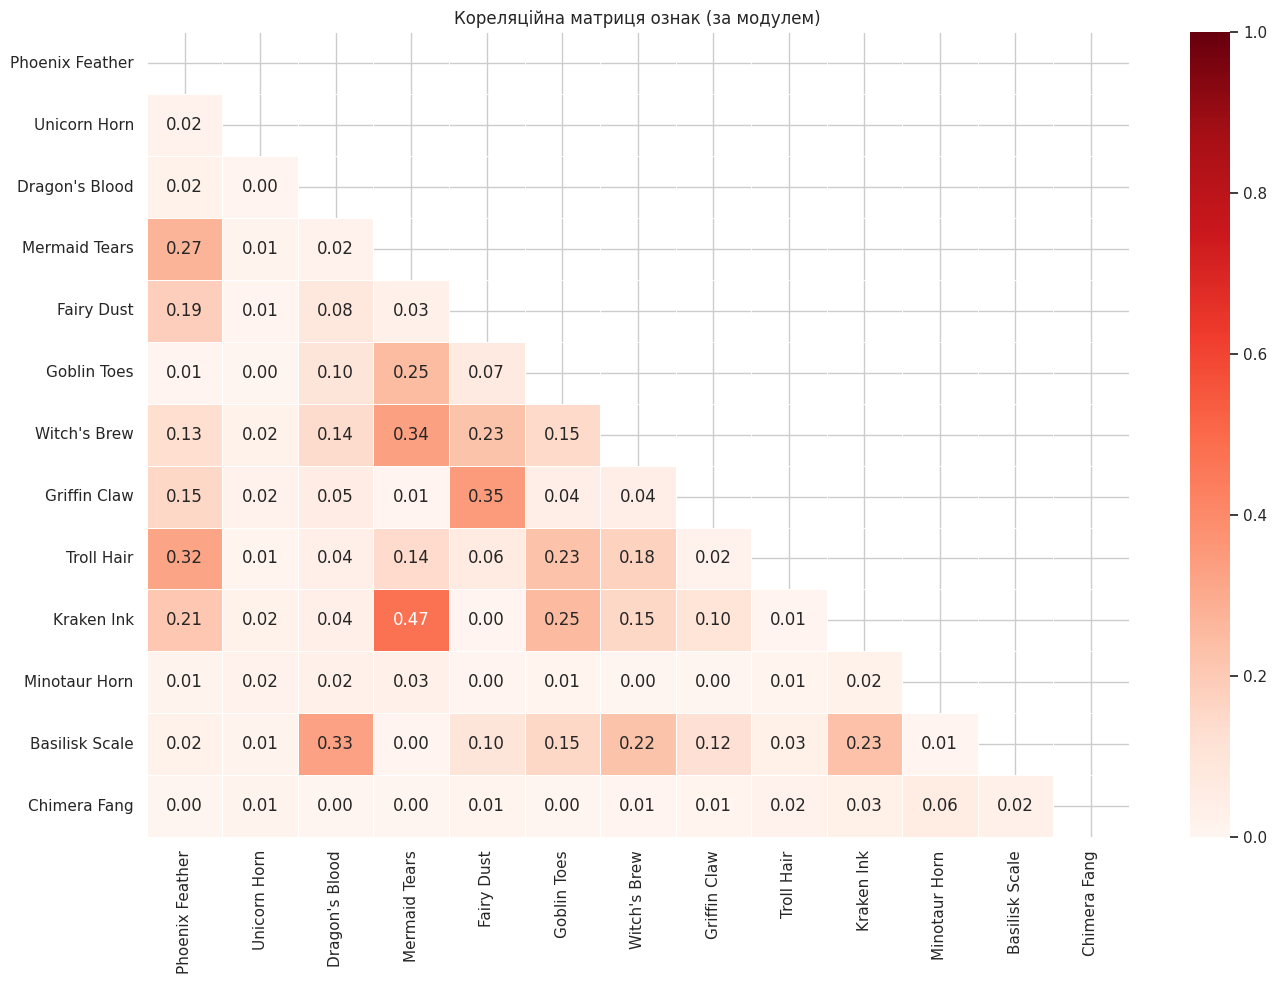

In [94]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
mtx = X_train.corr().abs()
mask = np.triu(
    np.ones_like(mtx, dtype=bool)
)
plt.figure(figsize=(14, 10))

sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    cmap='Reds',
    vmin=0,
    vmax=1,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Кореляційна матриця ознак (за модулем)')
plt.tight_layout()
plt.show()



In [95]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
corr_target = pd.concat(
    [X_train, y_train],
    axis=1
).corr()['Cured'].drop('Cured')

corr_target = corr_target.sort_values(
    key=abs,
    ascending=False
)
display(corr_target.to_frame(name='Кореляція з Cured'))

,Кореляція з Cured
Troll Hair,0.504026
Witch's Brew,0.237690
Basilisk Scale,-0.055086
Goblin Toes,0.049919
Kraken Ink,-0.037099
Phoenix Feather,0.024068
Unicorn Horn,-0.021990
Griffin Claw,-0.020528
Chimera Fang,0.018197
Dragon's Blood,0.016741


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [96]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("Розмір X_train_scaled:", X_train_scaled.shape)
print("Розмір X_test_scaled:", X_test_scaled.shape)
print(np.round(X_train_scaled.mean(axis=0), 3))
print(np.round(X_train_scaled.std(axis=0), 3))

Розмір X_train_scaled: (1870, 13)
Розмір X_test_scaled: (468, 13)
[-0. -0.  0. -0.  0.  0. -0. -0.  0.  0. -0. -0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [97]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report

model = LogisticRegression(
    random_state=42,
    max_iter=1000
)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)


print(f"\nAccuracy: {accuracy:.4f}")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


Accuracy: 0.8526
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

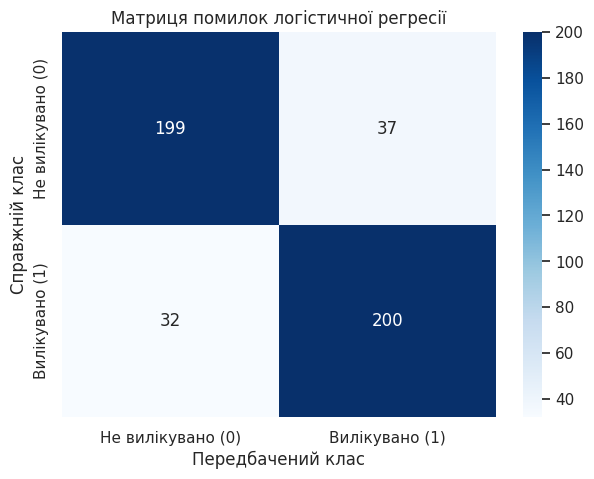

In [98]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)

conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    conf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не вилікувано (0)', 'Вилікувано (1)'],
    yticklabels=['Не вилікувано (0)', 'Вилікувано (1)']
)

plt.title('Матриця помилок логістичної регресії')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')

plt.show()



In [99]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
results = pd.DataFrame({
    'Справжній клас': y_test,
    'Передбачений клас': y_pred
})

results['Результат'] = np.where(
    results['Справжній клас'] == results['Передбачений клас'],
    'Правильно',
    'Помилка'
)


display(
    results.sample(
        n=min(10, len(results)),
        random_state=42
    )
)

,Справжній клас,Передбачений клас,Результат
1318,0,0,Правильно
244,0,0,Правильно
996,1,1,Правильно
930,0,0,Правильно
839,0,0,Правильно
1251,1,1,Правильно
335,1,1,Правильно
1670,0,0,Правильно
1118,0,0,Правильно
2175,1,1,Правильно


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
# Словник параметрів для GridSearchCV


In [ ]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри

In [100]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [500, 1000, 2000]
}

grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)
print(grid_search.best_params_)
print(round(grid_search.best_score_, 4))
print(grid_search.best_estimator_)

{'C': 10, 'max_iter': 500, 'solver': 'liblinear'}
0.8749
LogisticRegression(C=10, max_iter=500, random_state=42, solver='liblinear')


In [101]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [500, 1000, 1500, 2000, 3000]
}

random_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled, y_train)
print(random_search.best_params_)
print(round(random_search.best_score_, 4))
print(random_search.best_estimator_)

{'solver': 'lbfgs', 'max_iter': 3000, 'C': 10}
0.8749
LogisticRegression(C=10, max_iter=3000, random_state=42)


In [102]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
search_results = pd.DataFrame({
    'Метод': ['GridSearchCV', 'RandomizedSearchCV'],
    'Найкраща Accuracy (CV)': [
        grid_search.best_score_,
        random_search.best_score_
    ],
    'Найкращі параметри': [
        str(grid_search.best_params_),
        str(random_search.best_params_)
    ]
})

display(search_results)
if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
    best_search_name = 'GridSearchCV'
else:
    best_model = random_search.best_estimator_
    best_search_name = 'RandomizedSearchCV'
y_best_pred = best_model.predict(X_test_scaled)
best_accuracy = accuracy_score(y_test, y_best_pred)
print("\nНАЙКРАЩИЙ МЕТОД ПІДБОРУ:", best_search_name)
print(f"\nAccuracy на тестовій вибірці: {best_accuracy:.4f}")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_best_pred,
        zero_division=0
    )
)


,Метод,Найкраща Accuracy (CV),Найкращі параметри
0,GridSearchCV,0.874867,"{'C': 10, 'max_iter': 500, 'solver': 'liblinear'}"
1,RandomizedSearchCV,0.874867,"{'solver': 'lbfgs', 'max_iter': 3000, 'C': 10}"



НАЙКРАЩИЙ МЕТОД ПІДБОРУ: GridSearchCV

Accuracy на тестовій вибірці: 0.8504

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [103]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
models = {
    'Logistic Regression': best_model,

    'SVM': SVC(
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    )
}
model_results = []
predictions = {}
for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_model_pred = clf.predict(X_test_scaled)
    predictions[name] = y_model_pred
    acc = accuracy_score(y_test, y_model_pred)

    f1 = f1_score(
        y_test,
        y_model_pred,
        zero_division=0
    )

    model_results.append({
        'Модель': name,
        'Accuracy': acc,
        'F1-score': f1
    })

    print(f"\nМОДЕЛЬ: {name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1-score: {f1:.4f}")
comparison = pd.DataFrame(model_results)

comparison = comparison.sort_values(
    by='F1-score',
    ascending=False
).reset_index(drop=True)


display(comparison)


МОДЕЛЬ: Logistic Regression
Accuracy: 0.8504
F1-score: 0.8504

МОДЕЛЬ: SVM
Accuracy: 0.9338
F1-score: 0.9328

МОДЕЛЬ: Decision Tree
Accuracy: 0.8248
F1-score: 0.8240


,Модель,Accuracy,F1-score
0,SVM,0.933761,0.932755
1,Logistic Regression,0.850427,0.850427
2,Decision Tree,0.824786,0.824034


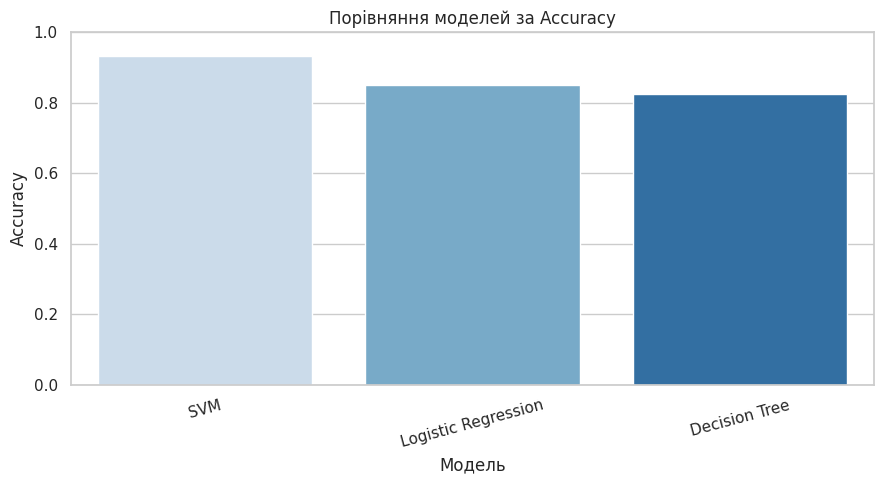

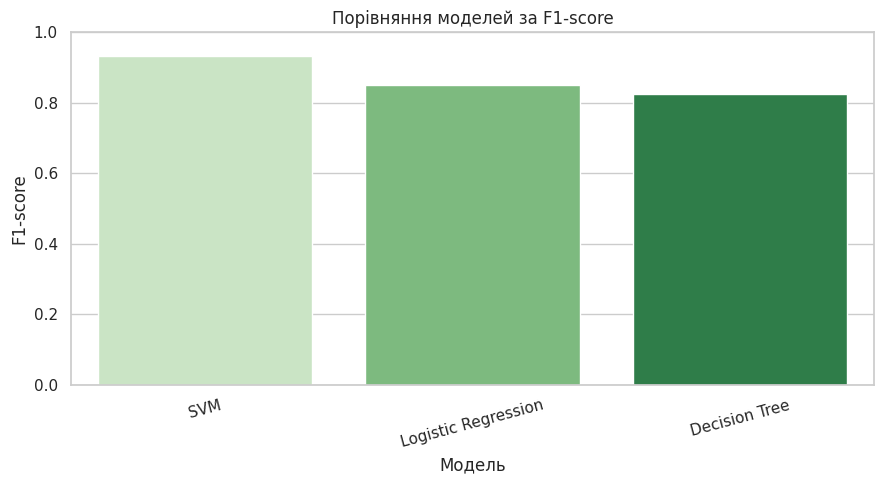

In [104]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x='Модель',
    y='Accuracy',
    hue='Модель',
    palette='Blues',
    legend=False
)

plt.title('Порівняння моделей за Accuracy')
plt.xlabel('Модель')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison,
    x='Модель',
    y='F1-score',
    hue='Модель',
    palette='Greens',
    legend=False
)

plt.title('Порівняння моделей за F1-score')
plt.xlabel('Модель')
plt.ylabel('F1-score')
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [105]:
best_model_name = comparison.iloc[0]['Модель']

best_model_accuracy = comparison.iloc[0]['Accuracy']
best_model_f1 = comparison.iloc[0]['F1-score']
display(comparison)
print("\nНАЙКРАЩА МОДЕЛЬ:", best_model_name)
print(f"Accuracy: {best_model_accuracy:.4f}")
print(f"F1-score: {best_model_f1:.4f}")


,Модель,Accuracy,F1-score
0,SVM,0.933761,0.932755
1,Logistic Regression,0.850427,0.850427
2,Decision Tree,0.824786,0.824034



НАЙКРАЩА МОДЕЛЬ: SVM
Accuracy: 0.9338
F1-score: 0.9328


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
_Впишіть відповідь тут._

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.